In [1]:
import numpy as np
import pandas as pd
import random
import datetime
from datetime import timedelta
import warnings
warnings.filterwarnings('ignore')
random.seed(27)

import tensorflow as tf
from keras import Model, Input
from keras.models import clone_model
from keras.layers import Dense
from keras.losses import Huber

## Defining Constants and Rates

In [3]:
#only Lar(97) and khirkiyan (5) has 306 kWh Battery Capacity
#efficiencies
mppt_efficiency = 1 #This efficiency is already taken in SolarPower
inverter_efficiency = 0.75
battery_efficiency = 0.98
rectifier_efficiency = 1 #This efficiency is already taken in BiomassPower
plant_efficiency = 1
distribution_efficiency = 0.9

#cost-rates
basic_price_per_kWh = 12470
battery_capacity = 204
cycle_derating = 0.25
charging_efficiency = 0.9
discharging_efficiency = 0.9
maintenance_cost_per_cycle = 75
interest_cost_on_capital = 2078713
dg_fuel_cost_per_kWh = 40
solar_cost_per_kWh = 3 #3
load_cost_per_kWh = 1
free_dg_turns = 3 
extra_dg_turn_cost = 0
plant_tripping_cost = 50000

#soc thresholds
min_soc = 38
max_soc = 100
day_min_soc = 45
day_max_soc_dg = 90
night_min_soc = 40
night_max_soc_dg = 50
plant_tripping_soc = 37
soc_buffer = 5
# safety_soc = 5

max_dg_power = 20 #32
min_dg_power = 0.5*max_dg_power

min_dg_steps = 3 #number of 15 minutes intervals we want dg to run atleast
# simulation_start_time = pd.to_datetime('2025-01-01 02:30:00')
# end_time = pd.to_datetime('2025-02-01 00:00:00')

last_reward = 0
total_reward = 0

## Environment Functions

In [5]:
def give_updated_soc(old_soc, 
                     solar_power_to_battery, mppt_efficiency, 
                     dg_power_to_battery, rectifier_efficiency,
                     battery_discharge_power, battery_efficiency, battery_capacity, minutes=15):
    #this function is required for simulation modelling purpose
    #this function won't be required in production
    solar_energy = solar_power_to_battery*mppt_efficiency*battery_efficiency*minutes/60
    battery_discharge_energy = battery_discharge_power*minutes/(60*battery_efficiency)
    dg_energy = dg_power_to_battery*rectifier_efficiency*battery_efficiency*minutes/60
    net_energy = (solar_energy+dg_energy) - battery_discharge_energy
    soc_change_in_percent = 100*net_energy/battery_capacity
    return min(100,max(-10,old_soc+soc_change_in_percent))

def battery_charging_power(soc,battery_capacity):
    if soc<=20:
        #%_of_battery_capacity
        bcp = 20
    elif soc>20 and soc<=35:
        bcp = 20
    elif soc>35 and soc<=40:
        bcp = 20
    elif soc>40 and soc<=50:
        bcp = 20
    elif soc>50 and soc<=55:
        bcp = 20
    elif soc>55 and soc<=60:
        bcp = 20
    elif soc>60 and soc<=75:
        bcp = 15
    elif soc>75 and soc<=80:
        bcp = 10
    elif soc>80 and soc<=85:
        bcp = 5
    elif soc>85 and soc<=95:
        bcp = 1
    else:
        bcp = 0.5
    return bcp #min(24,bcp*(battery_capacity/122))

def give_cycles_from_dod(dod):
    if dod<=20:
        return 4000
    elif dod>20 and dod<50:
        return 4000-(dod-20)*66.7
    elif dod>=50 and dod<60:
        return 2000-(dod-50)*35
    return 1650-(dod-60)*21.25

def battery_cost_per_kWh(soc,basic_price_per_kWh,battery_capacity,cycle_derating,
                         max_soc,charging_efficiency,discharging_efficiency,
                         maintenance_cost_per_cycle,interest_cost_on_capital,solar_cost_per_kWh):
    #this kWh cost is only applied to the energy coming out of the battery (load)
    dod = 100-soc
    cycles = (1-cycle_derating)*give_cycles_from_dod(dod)

    basic_price = battery_capacity*basic_price_per_kWh   #battery_capacity*soh
    maintenance_cost = cycles*maintenance_cost_per_cycle    #cycles_left = cycles-365*battery_age
    battery_charging_cost = cycles*battery_capacity*(max_soc-soc)*solar_cost_per_kWh/(charging_efficiency*100)
    # battery_charging_cost = cycles*battery_capacity*dod*solar_cost/(charging_efficiency*100)
    total_cost = basic_price + maintenance_cost + battery_charging_cost
    
    usable_capacity = battery_capacity*(max_soc-soc)*discharging_efficiency/100
    # usable_capacity = battery_capacity*dod*discharging_efficiency/100
    total_energy_supplied_by_battery = cycles*usable_capacity
    # print("soc:",soc,"dod:",dod,"cycles:",cycles,"usable_capacity:",usable_capacity,"total_energy:",total_energy_supplied_by_battery,"total_cost:",total_cost)
    # print("basic_price:",basic_price,"maintenance_cost:",maintenance_cost,"battery_charging_cost",battery_charging_cost)
    battery_lcoe = total_cost/total_energy_supplied_by_battery
    return battery_lcoe

battery_cost_per_kWh_map = {}
for soc in range(0,max_soc):
    battery_cost_per_kWh_map[soc] = battery_cost_per_kWh(soc,basic_price_per_kWh,battery_capacity,cycle_derating,
                         max_soc,charging_efficiency,discharging_efficiency,
                         maintenance_cost_per_cycle,interest_cost_on_capital,solar_cost_per_kWh)

In [7]:
def environment(state, action, sdf, gp):
    #state[0,1,2,3,4,5] -> year,month,weekday,day,hour,minute (t)
    #state[6] -> BatterySOC
                                            #state[2] -> BatteryDCVoltage    (Not Taken for Now)
    #state[7] -> SupplyPower (load_power)
    #state[8] -> SolarPower
    #state[9] -> dg_power
    #state[10] -> dg_status                 #state[10] -> dg_turns
    
    #action (t) can be 0 or 1
    # print("state",state)
    #if we receive ON command in buffer region then we need to hold the previous dg_status, else proceed further
    # if action==1 and max_soc_dg-soc_buffer<state[6]<=max_soc_dg:
        # print(f"{state[3],state[4],state[5]},SoC: {state[6]} is inside the buffer zone {max_soc_dg-soc_buffer,max_soc_dg}]. So holding the last dg_status:{state[11]}")
        # action = state[11]    #hold
            
    bat_cap_ah = (510/122)*battery_capacity
    max_bat_discharge_power = 0.2*bat_cap_ah*240/1000
    
    #solar_side_powers
    solar_demand_load_side = state[7]/(mppt_efficiency*inverter_efficiency)
    solar_demand_battery_side = battery_charging_power(state[6],battery_capacity)/(mppt_efficiency*battery_efficiency)
    solar_power = min(gp,solar_demand_load_side+solar_demand_battery_side)
    solar_power_wasted = max(0,gp-solar_power)
    solar_power_to_battery = max(0,solar_power-solar_demand_load_side)
    
    load_power_left = max(0,state[7]-solar_power*mppt_efficiency*inverter_efficiency)
    # print(solar_demand_load_side,solar_demand_battery_side,solar_power,solar_power_wasted,solar_power_to_battery,load_power_left)
    
    # safety_logic
    if state[6]<min_soc:# or load_power_left>max_bat_discharge_power:# or load_power_left>max_dg_power:
        action=1
    elif (0<=state[9]<min_dg_power and state[10]==1): #and state[6]>40
        # print(state[3],state[4],state[5],"Stopping DG as dg_power:",state[9],"is less than min_dg_power:",min_dg_power)
        action=0
    elif state[6]>max_soc_dg:
        # print(state[3],state[4],state[5],"Stopping DG as SoC:",state[6],"is greater than max_soc_dg of:",max_soc_dg)
        action=0
        
    dg_status = action
    #dg_side_powers
    dg_demand_load_side = load_power_left/(rectifier_efficiency*inverter_efficiency)
    battery_charging_power_left = battery_charging_power(state[6],battery_capacity)-solar_power_to_battery*mppt_efficiency*battery_efficiency
    dg_demand_battery_side = max(0,battery_charging_power_left)/(rectifier_efficiency*battery_efficiency)
    dg_power = dg_status*(min(max_dg_power,dg_demand_load_side+dg_demand_battery_side))
    dg_power_to_battery = min(dg_demand_battery_side,max(0,dg_power-dg_demand_load_side))

    load_power_left = max(0,load_power_left - dg_power*rectifier_efficiency*inverter_efficiency)
    # print(dg_demand_load_side,dg_demand_battery_side,dg_power,battery_charging_power_left,dg_power_to_battery,load_power_left)
    
    #battery_side_power
    battery_discharge_power = max(0,min(max_bat_discharge_power, load_power_left/(battery_efficiency*inverter_efficiency)))
    
    load_power_left = max(0,load_power_left - battery_discharge_power*inverter_efficiency) #considering battery discharge power taking account battery efficieny
    # print(battery_discharge_power,load_power_left)
    new_soc = give_updated_soc(state[6], 
                               solar_power_to_battery, mppt_efficiency, 
                               dg_power_to_battery, rectifier_efficiency,
                               battery_discharge_power, battery_efficiency, battery_capacity)
    
    avg_soc = (new_soc+state[6])/2

    #updating simulation df
    dg_turn_on = 0
    if state[10]==0 and dg_status==1:
        dg_turn_on = 1
        
    minute = round(state[4]*4 + state[5]/15)
    if len(sdf[sdf['minute']==minute])==0:
        sdf.loc[len(sdf)] = {'minute':minute, 'soc':avg_soc,'dg_power':dg_power,'battery_discharge_power': battery_discharge_power,
                                 'solar_power_wasted':solar_power_wasted,'load_power_left':load_power_left,'dg_turns':dg_turn_on}
    else:
        sdf.loc[sdf['minute']==minute,'soc'] = avg_soc
        sdf.loc[sdf['minute']==minute,'dg_power'] = dg_power
        sdf.loc[sdf['minute']==minute,'battery_discharge_power'] = battery_discharge_power
        sdf.loc[sdf['minute']==minute,'solar_power_wasted'] = solar_power_wasted
        sdf.loc[sdf['minute']==minute,'load_power_left'] = load_power_left
        sdf.loc[sdf['minute']==minute,'dg_turns'] = dg_turn_on
    
    return new_soc, avg_soc, battery_discharge_power, dg_power, solar_power, load_power_left, dg_turn_on, sdf, dg_status

## Reward Functions

In [9]:
#15_minutes reward function
def reward_function(avg_soc, battery_discharge_power,
                   dg_power,dg_fuel_cost_per_kWh,
                   solar_power_wasted,solar_cost_per_kWh,
                    load_power_left, load_cost_per_kWh,
                    dg_turns, free_dg_turns, extra_dg_turn_cost,
                    minutes=15):
    if round(avg_soc)>=100:
        bcp_kWh = battery_cost_per_kWh_map[99]
    else:
        bcp_kWh = battery_cost_per_kWh_map[round(avg_soc)]
    Battery_Cost = battery_discharge_power*bcp_kWh*minutes/60
    DG_Fuel_Cost = dg_power*dg_fuel_cost_per_kWh*minutes/60
    Waste_Solar_Energy_Cost = solar_power_wasted*solar_cost_per_kWh*minutes/60
    Unfulfilled_Load_Energy_Cost = load_power_left*load_cost_per_kWh*minutes/60
    DG_turning_cost = max(0,extra_dg_turn_cost*(dg_turns-free_dg_turns))
    Total_Cost = Waste_Solar_Energy_Cost+DG_turning_cost+DG_Fuel_Cost
    #Battery_Cost+DG_Fuel_Cost+Waste_Solar_Energy_Cost+Unfulfilled_Load_Energy_Cost+DG_turning_cost
    return -Total_Cost, -Battery_Cost, -DG_Fuel_Cost, -Waste_Solar_Energy_Cost, -Unfulfilled_Load_Energy_Cost,-DG_turning_cost
    
def simulation_score(sdf, soc, solar_power, i, df, mgp, dg_status, dg_power, previous_dict, hours=6):
    # print("I am inside simulation reward function.")
    # print("soc:",soc,"dg_power:",dg_power,"dg_status:",dg_status)
    future_sdf = pd.DataFrame(columns=['minute','soc','dg_power','battery_discharge_power','solar_power_wasted','load_power_left','dg_turns'])
    n = len(df)-20*4
    # initial_solar_power,initial_start_time,can_dg_run,j,cnt,take_shortage = soc,solar_power,df['CreatedonLocalTime'].iloc[i],0,i,0,1
    initial_soc,initial_dg_power,plant_trip,trip_distance,soc_min,initial_dg_status = soc,dg_power,0,24,100,dg_status
    
    start_time = df['CreatedonLocalTime'].iloc[i]
    end_time = start_time+timedelta(hours=hours)
        
    if soc<plant_tripping_soc:
        # print("Plant Trip!!, plant_tripping_soc:",plant_tripping_soc)
        plant_trip = 1
        trip_distance = 0

    if initial_dg_status==1:
        previous_dict['dg_running_steps']+=1
    else:
        previous_dict['dg_running_steps']=0
        
    t = df['CreatedonLocalTime'].iloc[i]
    mgp_i = mgp[mgp['CreatedonLocalTime']==t]['solar_power'].iloc[0]
    y,m,wd,d,h,mi,date = t.year,t.month,t.weekday(),t.day,t.hour,t.minute, t.date()
    current_minute = mi
    state = [y,m,wd,d,h,mi,soc,df['SupplyPower'].iloc[i],solar_power,dg_power,0,dg_status]

    # if (d==17 and h==14 and mi==15 and initial_dg_status==1):
    #     f=1
    # elif (d==17 and h==14 and mi==30 and initial_dg_status==1):
    #     f=2
    # elif (d==17 and h==14 and mi==45 and initial_dg_status==1):
    #     f=3
    # else:
    #     f=4
        
    # while start_time<=end_time and j<n-1:
    #     new_soc, avg_soc, batttery_discharge_power, dg_power, solar_power, load_power_left,dg_turn_on, future_sdf, dg_status = environment(state,1,future_sdf,mgp_i)                
    #     if cnt>=min_dg_run_count:
    #         can_dg_run=1
    #         # print("DG can run!!")
    #         break
    #     if dg_status:
    #         cnt+=1
    #     else:
    #         break
    #     j+=1
    #     start_time += timedelta(minutes=15)
    #     t = df['CreatedonLocalTime'].iloc[j]
    #     y,m,wd,d,h,mi,date = t.year,t.month,t.weekday(),t.day,t.hour,t.minute, t.date()
    #     mgp_i = mgp[mgp['CreatedonLocalTime']==t]['solar_power'].iloc[0]
    #     state = [y,m,wd,d,h,mi,new_soc,df['SupplyPower'].iloc[j],solar_power,dg_power,0,dg_status]
        
    #plant_trip
    # print("plant_trip")
    # soc,solar_power,dg_power,dg_status,start_time = initial_soc,initial_solar_power,initial_dg_power,initial_dg_status,df['CreatedonLocalTime'].iloc[i]
    # t = df['CreatedonLocalTime'].iloc[i]
    # mgp_i = mgp[mgp['CreatedonLocalTime']==t]['solar_power'].iloc[0]
    # y,m,wd,d,h,mi,date = t.year,t.month,t.weekday(),t.day,t.hour,t.minute, t.date()
    # state = [y,m,wd,d,h,mi,soc,df['SupplyPower'].iloc[i],solar_power,dg_power,0,dg_status]
    distance,interrupt,fulfilled_shortage = 0,0,0
    if (initial_dg_status==1) and previous_dict['dg_running_steps']<min_dg_steps:
        action=1
    else:
        action=0
    while start_time<=end_time and i<n-1:
        if 0<=h<=7:
            min_soc = night_min_soc
            max_soc_dg = night_max_soc_dg
        else:
            min_soc = day_min_soc
            max_soc_dg = day_max_soc_dg
        
        soc_min = min(soc_min,state[6])
        
        new_soc, avg_soc, batttery_discharge_power, dg_power, solar_power, load_power_left,dg_turn_off, future_sdf, dg_status = environment(state,action,future_sdf,mgp_i)        
        
        if dg_status==0:
            interrupt=1
            
        i += 1
        distance+=1
        start_time += timedelta(minutes=15)
        t = df['CreatedonLocalTime'].iloc[i]
        y,m,wd,d,h,mi,date = t.year,t.month,t.weekday(),t.day,t.hour,t.minute, t.date()
        mgp_i = mgp[mgp['CreatedonLocalTime']==t]['solar_power'].iloc[0]
        state = [y,m,wd,d,h,mi,new_soc,df['SupplyPower'].iloc[i],solar_power,dg_power,0,dg_status]

        total_steps = previous_dict['dg_running_steps']+distance
        if initial_dg_status==1 and total_steps<=min_dg_steps and interrupt==0:
        #if initially the dg was ON and total_steps are less than min_dg_steps and the run is uninterrupted then continue to turn ON else turn OFF
            action=1
            fulfilled_shortage+=dg_power
        else:
            action=0
        # print(t,h,t.date())
        # if f:
        #     log(m2,'HINUP-02-02',-1*f,t,state[8],state[7],dg_power, state[6], 0,0,i%4==0)        

        if new_soc<plant_tripping_soc:
            # print("Tripping soc:",new_soc,"Tripping time:",t,"plant_tripping_soc:", plant_tripping_soc)
            trip_distance = min(trip_distance,distance)
            plant_trip = 1
            # future_sdf.loc[future_sdf['minute']==mi,'dg_power']+=(plant_tripping_cost/10)
            # break
        
    # d = {}
    # for i in future_sdf.index:
    #     d[future_sdf['minute'][i]] = future_sdf['dg_power'][i]
    
    # print(j,list(d.keys()))
    # future_max_soc = future_sdf['soc'].max()
    # print("Total Shortage:",future_sdf['dg_power'].sum(),"Fulfilled Shortage:",fulfilled_shortage)
    shortage = future_sdf['dg_power'].sum()-fulfilled_shortage
    
    # if (max_soc_dg>soc>=max_soc_dg-soc_buffer and initial_dg_status==0) or (soc>max_soc_dg) or (future_max_soc>max_soc_dg):
    #     plant_trip,take_shortage = 0,0    #neutralize OFF
        
    # print("future max soc",future_sdf['soc'].max(),"is greater than max_soc_dg:",max_soc_dg)
    # print("Plant will trip after soc maxima. Not Considering Tripping.")
    # if max_soc_dg>future_sdf['soc'].max()>=max_soc_dg-soc_buffer:   #meaning I am inside buffer region or I will be inside buffer region
    #     print(f"max future soc inside buffer region [{max_soc_dg-soc_buffer},{max_soc_dg}]")
        # if initial_dg_status==0:# or max_soc_dg==day_max_soc_dg:
    #         # print("initially dg Off. future max soc",future_sdf['soc'].max(),"is greater than max_soc_dg-soc_buffer:",max_soc_dg-soc_buffer)
    #         # print("Not penalize off. Turning On is not allowed here.")
            # plant_trip = 0 #plant will trip after mid day or plant has reserve soc already
            # take_shortage = 0
    #     else:
    #         # print("initially dg On. future max soc",future_sdf['soc'].max(),"is greater than max_soc_dg-soc_buffer:",max_soc_dg-soc_buffer)            
    # el

    # if max(soc,future_max_soc)<max_soc_df-2*soc_buffer:
    #     shortage = shortage + safety_soc*battery_capacity
    # else:
    #     print("future max soc",future_sdf['soc'].max(),"is less than max_soc_dg-soc_buffer",max_soc_dg-soc_buffer)
    
    tc,bc,dc,sc,lc,dtc = reward_function(sdf['soc'].mean(), sdf['battery_discharge_power'].sum(),
                                     future_sdf['dg_power'].sum(),dg_fuel_cost_per_kWh,
                                     future_sdf['solar_power_wasted'].sum(),solar_cost_per_kWh,
                                     sdf['load_power_left'].sum(), load_cost_per_kWh,
                                    sdf['dg_turns'].sum(), free_dg_turns, extra_dg_turn_cost)
        
    #"No. of Turns:",sdf['dg_turns'].sum(), "Turning Cost:",dtc, "sc:",-sc,"sp:",sp,"sc-dtc:",-sc+dtc)
    # print(initial_start_time,"soc:",round(soc,1),"tripping cost:",-plant_tripping_cost*plant_trip,
    #           "waste solar cost:",-sc,"turning cost:",-dtc,"shortage cost:",take_shortage*round(future_sdf['dg_power'].sum()*10,1),
    #           "initial dg status:",initial_dg_status,"#turns:",sdf['dg_turns'].sum())

    #waste solar cost and turning cost are reducing naturally so no need of giving reward of reducing them.
    # if abs(previous_dict['turning_cost'])>abs(dtc):
    #     previous_dict['turning_cost'] = dtc
    # if abs(previous_dict['waste_solar_cost'])>abs(sc):
    #     previous_dict['waste_solar_cost'] = sc
    # if previous_dict['trip_distance']>trip_distance:
    #     previous_dict['trip_distance'] = trip_distance
        
    # previous_minute = current_minute-1
    # if previous_minute==-1:
    #     previous_minute = 23    
    
    rd = {'soc_min':soc_min,'shortage':shortage,'waste_solar_cost':sc,'turning_cost':dtc,'trip_distance':trip_distance,
          'fulfilled_shortage':previous_dict['fulfilled_shortage'], 'dg_running_steps':previous_dict['dg_running_steps']} #reward_dictionary
    # rd['fulfilled_shortage'] = 0
    # print("rd:",rd)
    # previous_dict['shortage'][previous_minute] = 0
    # d[previous_minute] = 0
    # if previous_dict['shortage']-shortage>0:
    #     shortage_fulfilled = 1
    # else:
    #     shortage_fulfilled = 0

    # shortage_reward = (previous_dict['shortage']-shortage)*10
    # rd['fulfilled_shortage'] = shortage_fulfilled*(previous_dict['fulfilled_shortage']+shortage_reward)
    
    # take_turning_cost = 0
    # if shortage_fulfilled==0 and rd['fulfilled_shortage']<extra_dg_turn_cost:
    #     take_turning_cost=1
        
    # extra_dg_fuel_penalize = -(1-shortage_fulfilled)*initial_dg_power*10
    # plant_trip_penalize = -plant_tripping_cost*plant_trip
    # plant_trip_save_reward = (rd['trip_distance']-previous_dict['trip_distance'])*(plant_tripping_cost/90)
    
    # change = rd['waste_solar_cost']-previous_dict['waste_solar_cost'] +take_turning_cost*(rd['turning_cost'] - previous_dict['turning_cost'])
    # print("change:",change,"shortage_reward:",shortage_reward,"plant_trip_save_reward:",plant_trip_save_reward,"extra_dg_fuel_penalize:",extra_dg_fuel_penalize)
    # change = change +shortage_reward +plant_trip_save_reward +extra_dg_fuel_penalize #+plant_trip_penalize 

    # print("previous_dict:",previous_dict,"rd:",rd,"plant_will_trip:",plant_will_trip)
    # if initial_soc<min_soc and plant_trip==0:    #neutralizing reward in min soc zone, just giving plant_trip penalization
    #     change = 0
    # if initial_dg_status==0:
    #     nr = -can_dg_run*(take_shortage*shortage*10) + 150*can_dg_run + 100*(1-can_dg_run) #plant_tripping_cost*plant_trip + 
        # if abs(dtc)>0:
        #     nr = nr+extra_dg_turn_cost
    # print("net reward",nr)#,"end minute",end_minute)
            
    return rd #, change

## Loading Solcast-Live and Load_Power Data

In [11]:
#solcast live
solar = pd.read_parquet('solcast_live/Solcast_Live_06_2025.parquet')
gp = solar[(solar['PlantCode']=='HINUP-02-02')]

df = pd.read_csv('004/Jun_2025_004.csv')

df['CreatedonLocalTime'] = pd.to_datetime(df['CreatedonLocalTime'])
df.sort_values(['PlantCode','CreatedonLocalTime'],inplace=True)

#solar forecast
sf = pd.read_parquet('solcast_forecast/Solcast_forecast_06_2025.parquet')
sf = sf[(sf['PlantCode']=='HINUP-02-02')]
# sf['period_end'] = pd.to_datetime(sf['period_end'])+timedelta(hours=5,minutes=30) #from Feb 2025 onwards
# sf['period_end'] = sf['period_end'].dt.tz_localize(None)
# sf['local_hour'],sf['local_date'] = sf['period_end'].dt.hour,sf['period_end'].dt.date

for file in [gp,sf]:
    file['period_end'] = pd.to_datetime(file['period_end'])+timedelta(hours=5,minutes=30) #from Feb 2025 onwards
    file['period_end'] = file['period_end'].dt.tz_localize(None)
    file['local_hour'],file['local_date'] = file['period_end'].dt.hour,file['period_end'].dt.date

#load forecast
lf = pd.read_parquet('combined_file_V2.parquet')
lf = lf[lf['PlantId']==19]
lf['local_hour'] = lf['IST_date'].dt.hour #LastEnergyDatetime
lf['local_date'] = lf['IST_date'].dt.date

In [97]:
df['x'] = 0
for i in range(1,len(df)):
    df['x'][i] = df['PlantlifetimeEnergy'][i]-df['PlantlifetimeEnergy'][i-1]
df['x'] = df['x']*4
df['SupplyPower'] = df['x']

In [25]:
for i in df[df['SupplyPower']>12].index:
    df.loc[i,'SupplyPower'] = 12
    
df.loc[1539,'BiomassPower'] = 15
df.loc[1540,'BiomassPower'] = 15
df.loc[1539,'BiomassPower'] = 2.68
df.loc[1540,'SupplyPower'] = 2.68
df.loc[1542,'SupplyPower'] = 2.68

## Training Parameters of RL Model

In [13]:
# Parameters
epsilon = 1
epsilon_decay = 1.1
gamma = 0.99
num_episodes = 400

max_transitions = 10**5    #enough
min_buffer_size = 1000
replay_buffer = []
batch_size = 64 #24*4    #24hours
target_update_after = 10*24*4 #3days
learn_after_steps = 1*3 #1hour
skip_each_episode = 2

net_input = Input(shape=(19,))
x = Dense(64,activation="relu")(net_input)    #1st layer of 64 nodes
x = Dense(64,activation="relu")(x)    #2nd layer of 64 nodes
# x = Dense(64,activation="relu")(x)    #3rd layer of 64 nodes
output = Dense(2,activation="linear")(x)
q_net = Model(inputs=net_input, outputs=output)
q_net.compile(optimizer="adam")
loss_fn = Huber()

target_net = clone_model(q_net)

In [15]:
def insert_transition(transition):
    if len(replay_buffer) >= max_transitions:
        replay_buffer.pop(0)
    replay_buffer.append(transition)

def sample_transitions(batch_size):
    # random_index = random.randint(0,len(replay_buffer)-1)
    # rdx = [random.randint(0, len(replay_buffer)-1) for _ in range(min(batch_size,len(replay_buffer)))]
    random_indices = tf.random.uniform(shape=(batch_size,),minval=0,maxval=len(replay_buffer),dtype=tf.int32)
    sample_current_states,sample_actions,sample_rewards,sample_next_states = [],[],[],[]
    # print("random_index:",random_index)
    # for i in range(random_index,min(random_index+batch_size,len(replay_buffer))):
    for i in random_indices:
        # print("i:",i)
        sample_current_states.append(replay_buffer[i][0])
        sample_actions.append(replay_buffer[i][1])
        sample_rewards.append(replay_buffer[i][2])
        sample_next_states.append(replay_buffer[i][3])

    return tf.convert_to_tensor(sample_current_states),tf.convert_to_tensor(sample_actions),tf.convert_to_tensor(sample_rewards),tf.convert_to_tensor(sample_next_states)
    
def policy(state,explore=0):
    action = tf.argmax(q_net(tf.expand_dims(state, axis=0))[0],output_type=tf.int32)
    if tf.random.uniform(shape=(), maxval=1) <= explore:
        action = tf.random.uniform(shape=(), minval=0, maxval=2, dtype=tf.int32)
    return action

def monitor_q_values(model, states, step=None):
    q_values = model(states, training=False)  # shape: (batch_size, num_actions)
    q_values_np = q_values.numpy()

    mean_q = np.mean(q_values_np)
    max_q = np.max(q_values_np)
    min_q = np.min(q_values_np)
    std_q = np.std(q_values_np)

    if step is not None:
        print(f"[Step {step}] Q-values: mean={mean_q:.3f}, max={max_q:.3f}, min={min_q:.3f}, std={std_q:.3f}")
    else:
        print(f"Q-values: mean={mean_q:.3f}, max={max_q:.3f}, min={min_q:.3f}, std={std_q:.3f}")

    return mean_q
        
def log(m2, pc, episode, time, solar_power, load_power, dg_power, soc, avg_soc,actual_dg_power,insert):
    m2['pc'].append(pc)
    m2['episode'].append(episode)
    m2['time'].append(time)
    m2['solar_power'].append(solar_power)
    m2['load_power'].append(load_power)
    m2['dg_power'].append(dg_power)
    m2['soc'].append(soc)
    m2['avg_soc'].append(avg_soc)
    m2['actual_dg_power'].append(actual_dg_power)
    if insert:
        pd.DataFrame(m2).to_csv("metric.csv", index=False)
        # print(time, "metric.csv updated")

def give_forecast(quantity,duration,date,hour):
    start_time = pd.to_datetime(date)+timedelta(hours=hour+1)
    end_time = pd.to_datetime(date)+timedelta(hours=hour+duration)
    # print(date,hour,start_time,end_time)
    if quantity=='solar':
        x = sf[(sf['period_end']>=start_time) & (sf['period_end']<=end_time)].drop_duplicates('local_hour',keep='first')
        return x['pv_power_rooftop'].sum()
    else:
        #LastEnergyDatetime, return lf[(lf['IST_date']>=start_time) & (lf['IST_date']<=end_time)]['prediction_365'].sum()
        tmp_lf = lf[(lf['IST_date']>=start_time) & (lf['IST_date']<=end_time)]
        tmp_lf.sort_values('file_creation_date',ascending=False, inplace=True)
        tmp_lf.drop_duplicates('IST_date',keep='first',inplace=True)
        return tmp_lf['prediction_365'].sum()

In [17]:
#modified Generation Potential
mgp = pd.DataFrame(columns = ['CreatedonLocalTime','solar_power','dg_power'])
m2 = {"pc":[],"episode":[],"time":[],"solar_power":[],"load_power":[],"dg_power":[],"soc":[],"avg_soc":[],"actual_dg_power":[]}

i = 96*0
t = df['CreatedonLocalTime'].iloc[i]
y,m,wd,d,h,mi,date = t.year,t.month,t.weekday(),t.day,t.hour,t.minute,t.date()
gp_i = gp[(gp['local_hour']==h) & (gp['local_date']==date)]['pv_power_rooftop'].iloc[0]
# mgp.loc[len(mgp)] = {'CreatedonLocalTime':t, 'solar_power':df['SolarPower'].iloc[i],'dg_power':0}
state = [y,m,wd,d,h,mi,df['BatterySOC'].iloc[i],df['SupplyPower'].iloc[i],df['SolarPower'].iloc[i],0,0,0]

n = 96*18 #len(df)-96*1
dgp,lpl = 0,0
while i < n:
    if 0<=h<=7:
        min_soc = night_min_soc
        max_soc_dg = night_max_soc_dg
    else:
        min_soc = day_min_soc
        max_soc_dg = day_max_soc_dg
    sdf = pd.DataFrame(columns=['minute','soc','dg_power','battery_discharge_power','solar_power','load_power_left','dg_turns'])
    new_soc, avg_soc, battery_discharge_power, dg_power, solar_power, load_power_left, dg_turn_off, sdf, dg_status = environment(state,0,sdf,gp_i)
    lpl+=load_power_left
    mgp.loc[len(mgp)] = {'CreatedonLocalTime':t, 'solar_power':solar_power,'dg_power':dg_power}
    
    log(m2,'HINUP-02-02',-1,t,state[8],state[7],dg_power, state[6], df['BatterySOC'].iloc[i],df['BiomassPower'].iloc[i],i%50==0)#df['BatterySOC'].iloc[i],df['BiomassPower'].iloc[i]
    
    i+=1
    t = df['CreatedonLocalTime'].iloc[i]
    y,m,wd,d,h,mi,date = t.year,t.month,t.weekday(),t.day,t.hour,t.minute,t.date()
    gp_i = gp[(gp['local_hour']==h) & (gp['local_date']==date)]['pv_power_rooftop'].iloc[0]
    next_state = [y,m,wd,d,h,mi,new_soc,df['SupplyPower'].iloc[i],solar_power,dg_power,sdf['dg_turns'].sum(),dg_status]
    
    state = next_state
    dgp+=dg_power
print("Minimum DG Cost:",(dgp/4)*40,"Solar Energy Generated:",mgp['solar_power'].sum()/4,"Min SOC:",pd.DataFrame(m2)['soc'].min(),"load power left:",load_power_left)

Minimum DG Cost: 10800.0 Solar Energy Generated: 3519.204191825678 Min SOC: 36.908393610280186 load power left: 0


In [171]:
pd.DataFrame(m2).drop(['episode','pc','actual_dg_power','avg_soc'],axis=1).to_excel('Partawal_Chowk_Apr_25_204.xlsx',index=False)

In [19]:
i=96*0
n=96*18
forecast = pd.DataFrame(columns=['time','1hr_load','1hr_solar','6hr_load','6hr_solar','12hr_load','12hr_solar','24hr_load','24hr_solar'])

while i<n:
    t=df['CreatedonLocalTime'][i]
    date,h = t.date(),t.hour
    forecast.loc[len(forecast)] = {'time':t,
                                         '1hr_load':give_forecast('load',1,date,h),'1hr_solar':give_forecast('solar',1,date,h),
                                         '6hr_load':give_forecast('load',6,date,h),'6hr_solar':give_forecast('solar',6,date,h),
                                         '12hr_load':give_forecast('load',12,date,h),'12hr_solar':give_forecast('solar',12,date,h),
                                         '24hr_load':give_forecast('load',24,date,h),'24hr_solar':give_forecast('solar',24,date,h)}
    # {'time':t,'1hr_load':give_forecast('load',1,date,h),'1hr_solar':give_forecast('solar',1,date,h),
    #                                      '6hr_load':give_forecast('load',6,date,h),'6hr_solar':give_forecast('load',6,date,h),
    #                                      '12hr_load':give_forecast('load',12,date,h),'12hr_solar':give_forecast('solar',12,date,h),
    #                                      '24hr_load':give_forecast('load',24,date,h),'24hr_solar':give_forecast('solar',24,date,h)}
    i+=1

In [21]:
# metric = {"pc":[],"Episode":[], "Reward":[], "Epsilon":[], "Logs":[]}
m2 = {"pc":[],"episode":[],"time":[],"solar_power":[],"load_power":[],"dg_power":[],"soc":[],"avg_soc":[],"actual_dg_power":[]}

pc = 'HINUP-02-02'
print(pc)

df['BatterySOC'] = df['BatterySOC'].replace(0,np.nan).fillna(method='ffill').fillna(method='bfill')
for episode in range(num_episodes):
    sdf = pd.DataFrame(columns=['minute','soc','dg_power','battery_discharge_power','solar_power_wasted','load_power_left','dg_turns'])
    # sdf.loc[len(sdf)] = {'soc':0}
    total_reward,bat_cost,dg_cost,cuf_cost,load_cost,turn_cost = 0,0,0,0,0,0
    dg_power,dg_turns,dg_status,shortage_fulfilled = 0,0,0,0
    target_updated = 0
    simulation_dict = {'soc_min':100,'shortage':0,'waste_solar_cost':0,'turning_cost':0,'trip_distance':24,'fulfilled_shortage':0,
                      'dg_running_steps':0}
    soc=[]
    logs=[]
    var_soc=[]
    i=96*0
    i_init = i
    n = 96*18 #len(df)-96*1 #96*15   

    t = df['CreatedonLocalTime'].iloc[i]
    mgp_i = mgp[mgp['CreatedonLocalTime']==t]['solar_power'].iloc[0]     #modified gp at time t. (soc,mgp_i)->(new_soc,mgp_i+1)
    forecast_i = forecast[forecast['time']==t]
    y,m,wd,d,h,mi,date = t.year,t.month,t.weekday(),t.day,t.hour,t.minute,t.date()
    state = [y,m,wd,d,h,mi,df['BatterySOC'].iloc[i],df['SupplyPower'].iloc[i],df['SolarPower'].iloc[i],dg_power,dg_status, #0,dg_turns,
             forecast_i['1hr_load'].iloc[0],forecast_i['1hr_solar'].iloc[0],forecast_i['6hr_load'].iloc[0],forecast_i['6hr_solar'].iloc[0],
             forecast_i['12hr_load'].iloc[0],forecast_i['12hr_solar'].iloc[0],forecast_i['24hr_load'].iloc[0],forecast_i['24hr_solar'].iloc[0]] 
    # df['BatteryDCVoltage'].iloc[i],
    
    while i<n-1:
        if 0<=h<=7:
            min_soc = night_min_soc
            max_soc_dg = night_max_soc_dg
        else:
            min_soc = day_min_soc
            max_soc_dg = day_max_soc_dg
        
        action = policy(state,epsilon)
        tmp_new_soc, _, _, tmp_dg_power, tmp_solar_power, _, _, tmp_sdf, tmp_dg_status = environment(state,1-action.numpy(),sdf.copy(),mgp_i)
        new_soc, avg_soc, battery_discharge_power, dg_power, solar_power, load_power_left, dg_turn_on, sdf, dg_status = environment(state,action.numpy(),sdf,mgp_i)
        
        turns = sdf['dg_turns'].sum()
        turn_15_min = 0
        if turns>free_dg_turns and dg_turn_on:
            turn_15_min = 1
            
        current_reward,bc,dc,sc,lc,tc = reward_function(sdf['soc'].mean(), battery_discharge_power,
                                dg_power, dg_fuel_cost_per_kWh,
                                max(0,mgp_i-solar_power), solar_cost_per_kWh,
                                load_power_left, load_cost_per_kWh,
                                free_dg_turns+turn_15_min, free_dg_turns, extra_dg_turn_cost)

        diff_soc = round(state[6])-round(df['BatterySOC'].iloc[i])              
        
        i+=1
        t = df['CreatedonLocalTime'].iloc[i]
        y,m,wd,d,h,mi,date = t.year,t.month,t.weekday(),t.day,t.hour,t.minute,t.date()
        mgp_i = mgp[mgp['CreatedonLocalTime']==t]['solar_power'].iloc[0]
        forecast_i = forecast[forecast['time']==t]
        next_state = [y,m,wd,d,h,mi,new_soc,df['SupplyPower'].iloc[i],solar_power,dg_power,dg_status,#simulation_dict['dg_running_steps'],sdf['dg_turns'].sum(),
                      forecast_i['1hr_load'].iloc[0],forecast_i['1hr_solar'].iloc[0],forecast_i['6hr_load'].iloc[0],forecast_i['6hr_solar'].iloc[0],
                      forecast_i['12hr_load'].iloc[0],forecast_i['12hr_solar'].iloc[0],forecast_i['24hr_load'].iloc[0],forecast_i['24hr_solar'].iloc[0]] 

        tmp_next_state = [y,m,wd,d,h,mi,tmp_new_soc,df['SupplyPower'].iloc[i],tmp_solar_power,tmp_dg_power,tmp_dg_status]  #,tmp_sdf['dg_turns'].sum()

        change_rf=0
        
        if state[6]>=min_soc and state[6]<=max_soc_dg:
            # print("1. sd:",simulation_dict)
            tmp_simulation_dict = simulation_score(tmp_sdf,tmp_next_state[6], tmp_next_state[8], i, df, mgp, tmp_next_state[10], 
                                                                   tmp_next_state[9], simulation_dict.copy(), 24)
            # print(tmp_simulation_dict)
            simulation_dict = simulation_score(sdf,next_state[6], next_state[8], i, df, mgp, next_state[10], 
                                                                   next_state[9], simulation_dict.copy(), 24)
            # print(simulation_dict)

            if state[10]==1 and action.numpy()==1:
                # I am in On State, taken On action
                if (tmp_simulation_dict['shortage']-simulation_dict['shortage'] + shortage_fulfilled >=50) and simulation_dict['shortage']>0:
                    #If I am able to fulfill more than 50 kW shortage then reward with DG_Status*200
                    change_rf = next_state[10]*200
                    shortage_fulfilled+= next_state[9]
                else:
                    #If I cannot fulfill more than 50 kW shortage then penalize with -DG_Status*200
                    change_rf = -next_state[10]*200
            elif state[10]==1 and action.numpy()==0:
                # I am in On State, taken Off action
                if (simulation_dict['shortage']-tmp_simulation_dict['shortage'] + shortage_fulfilled >=50) and tmp_simulation_dict['shortage']>0:
                    #If I am able to fulfill more than 50 kW shortage then I am wasting with DG_Status*200
                    change_rf = -tmp_next_state[10]*200
                else:
                    #If I cannot fulfill more than 50 kW shortage then I am saving with DG_Status*200
                    change_rf = tmp_next_state[10]*200
            elif state[10]==0 and action.numpy()==1:
                # I am in Off state, taken On action.
                if (tmp_simulation_dict['shortage']-simulation_dict['shortage']>=50) and simulation_dict['shortage']>0:
                    #If I am able to Run DG 45 mins uninterrupted and fulfill more than 50kW shortage then reward with DG_Status*200
                    change_rf = next_state[10]*200
                    shortage_fulfilled+= next_state[9]
                else:
                    #If I cannot Run DG 45 mins uninterrupted and fulfill more than 50kW shortage then I am wasting -DG_Status*200 
                    change_rf = -next_state[10]*200
            elif state[10]==0 and action.numpy()==0:
                # I am in Off state, taken Off action.
                if (simulation_dict['shortage']-tmp_simulation_dict['shortage']>=50) and tmp_simulation_dict['shortage']>0:
                    #If I am able to Run DG 45 mins and fulfill more than 50kW shortage uninterrupted then penalize with DG_Status*200
                    change_rf = -tmp_next_state[10]*200
                else:
                    #If I cannot Run DG 45 mins uninterrupted and fulfill more than 50kW shortage then I am saving DG_Status*200
                    change_rf = tmp_next_state[10]*200
                
            # cond = (tmp_simulation_dict['shortage']==simulation_dict['shortage']) and (abs(tmp_simulation_dict['soc_min']-simulation_dict['soc_min'])<1.5)
            # if cond and (simulation_dict['trip_distance']==tmp_simulation_dict['trip_distance']):
            #     # simulation_dict['fulfilled_shortage']=0
            #     shortage_fulfilled=0
            # elif max(dg_power,tmp_dg_power)>min_dg_power:
            #     shortage_fulfilled=1
            #     if action.numpy():
            #         simulation_dict['fulfilled_shortage']+=((tmp_simulation_dict['shortage']-simulation_dict['shortage'])*10)                
            #         simulation_dict['fulfilled_shortage']+=((simulation_dict['soc_min']-tmp_simulation_dict['soc_min'])*80)
            #         simulation_dict['fulfilled_shortage']+=(simulation_dict['trip_distance']-tmp_simulation_dict['trip_distance'])*(plant_tripping_cost/90)

            # # print("shortage_fulfilled:",("Yes" if shortage_fulfilled else "No"))
            
            # take_turning_cost=0
            # if simulation_dict['fulfilled_shortage']<extra_dg_turn_cost and (next_state[11]==0 or shortage_fulfilled==0):
            #     take_turning_cost=1
                
            # if take_turning_cost==1:
            #     if state[11]==1 and next_state[11]==0 and sdf['dg_turns'].sum()>free_dg_turns:
            #         change_rf -= extra_dg_turn_cost
            #     elif shortage_fulfilled==0:# action.numpy()==1:
            #         change_rf += (simulation_dict['turning_cost'] - tmp_simulation_dict['turning_cost'])
                
            #     # print("Taking Turning Cost!!, change_rf:",change_rf)
            
            # if next_state[11]==0 or simulation_dict['fulfilled_shortage']<0 or shortage_fulfilled==0:
            #     simulation_dict['fulfilled_shortage'] = 0

            change_rf+= (simulation_dict['waste_solar_cost']-tmp_simulation_dict['waste_solar_cost'])
            
            # if max(dg_power,tmp_dg_power)>min_dg_power:
            #     change_rf+= ((tmp_simulation_dict['shortage']-simulation_dict['shortage'])*10)
            # change_rf+= (take_turning_cost*(simulation_dict['turning_cost'] - tmp_simulation_dict['turning_cost']))
            # change_rf+= ((simulation_dict['trip_distance']-tmp_simulation_dict['trip_distance'])*(plant_tripping_cost/90))
            
            # if min(tmp_simulation_dict['soc_min'],simulation_dict['soc_min'])<min_soc or abs(simulation_dict['soc_min']-tmp_simulation_dict['soc_min'])>=1.5:
            #     change_rf+= ((simulation_dict['soc_min']-tmp_simulation_dict['soc_min'])*80)
            
            # if state[6]>min_soc:
            #     change_rf+= -(1-shortage_fulfilled)*next_state[9]*10
            # print("extra_dg_fuel_penalize:",-(1-shortage_fulfilled)*next_state[9]*10,"fulfilled_shortage:",simulation_dict['fulfilled_shortage'])
        # print("3. sd:",simulation_dict,"3. tmp_sd:",tmp_simulation_dict)
        
        # change_rf = score-tmp_score
        # print("Params:",df['CreatedonLocalTime'].iloc[i-1],state[6],action.numpy(),shortage_fulfilled,change_rf,"\n")
        
        if dg_status==0:
            shortage_fulfilled=0
        shortage_fulfilled=min(50,shortage_fulfilled)
        # if state[6]<plant_tripping_soc:
        #     change_rf-=plant_tripping_cost
        if change_rf!=0:
            change_rf = change_rf/200
        # next_state[12] = simulation_dict['dg_running_steps']            
        
        log(m2,pc,episode,df['CreatedonLocalTime'].iloc[i-1],state[8],state[7],state[9], state[6],change_rf*10,action.numpy()*15,i%40==0)#df['BatterySOC'].iloc[i],df['BiomassPower'].iloc[i]

        if i!=(i_init+1) and state[6]<max_soc_dg and state[6]>min_soc and (dg_status!=tmp_dg_status):    
            #no need to insert safety region and max region txns
            # print("txn inserted.")
            insert_transition([state,action,change_rf,next_state])
        # print(len(state),action,change_rf,len(next_state))
        
        if i%learn_after_steps==0 and i!=(i_init+1) and state[6]<max_soc_dg and state[6]>min_soc and len(replay_buffer)>min_buffer_size: 
            #no need to learn in safety & max regions
            current_states, actions, rewards, next_states = sample_transitions(batch_size)
            
            # Step 1: Get the best next actions from the online network (q_net)
            next_q_values_online = q_net(next_states)
            best_next_actions = tf.cast(tf.argmax(next_q_values_online, axis=1), dtype=tf.int32)
            
            # Step 2: Evaluate these actions using the target network
            next_q_values_target = target_net(next_states)
            batch_nums = tf.range(tf.shape(next_states)[0])
            indices = tf.stack([batch_nums, best_next_actions], axis=1)
            selected_target_q_values = tf.gather_nd(next_q_values_target, indices)
            
            # Step 3: Compute targets using Double DQN logic
            rewards = tf.cast(rewards, tf.float32) 
            targets = rewards + gamma * selected_target_q_values

            # next_action_values = tf.reduce_max(target_net(next_states), axis=1)
            # targets = change_rf + gamma*next_action_values
            
            with tf.GradientTape() as tape:
                preds = q_net(current_states)
                batch_nums = tf.range(0,limit=min(batch_size,len(actions)))
                indices = tf.stack((batch_nums, actions), axis=1)
                # print("indices:",indices)
                current_values = tf.gather_nd(preds, indices)
                loss = loss_fn(targets, current_values)
    
            grads = tape.gradient(loss, q_net.trainable_weights)
            q_net.optimizer.apply_gradients(zip(grads, q_net.trainable_weights))
            # print("Weights are trained!!!")
                  
        if i%target_update_after==0 and episode%skip_each_episode==0 and len(replay_buffer)>min_buffer_size :
            #i>target_update_after and target_updated==0
            target_net.set_weights(q_net.get_weights())
            print("Target Network is updated!!!")
            # target_updated=1
        
        soc.append(new_soc)
        var_soc.append(diff_soc)
        total_reward+=current_reward
        bat_cost+=bc
        dg_cost+=dc
        cuf_cost+=sc
        load_cost+=lc
        turn_cost+=change_rf #tc
        # logs.append([round(total_reward,2), change_rf, current_reward, t-timedelta(minutes=15) ,round(state[6],2), round(df['SupplyPower'].iloc[i-1],2),round(mgp_i,2), dg_power, bc, dc, sc, round(lc,2), tc, action.numpy()])
        state = next_state
    # metric["pc"].append(pc)
    # metric["Episode"].append(episode)
    # metric["Reward"].append(-total_reward)
    # metric["Epsilon"].append(epsilon)
    # metric["Logs"].append(logs)
    states,a,b,c = sample_transitions(batch_size)
    mq = monitor_q_values(q_net,states,episode)
    log(m2,pc,episode,df['CreatedonLocalTime'].iloc[i-1],mq,round(turn_cost,2),None, None,None,None,1)
    print("Episode:",episode, "Total Cost:",-round(total_reward,1), "Epsilon:",round(epsilon,3), "SOC:",round(sum(soc)/len(soc),3),
          "DG Cost:",-round(dg_cost,3),"CUF Cost:",-round(cuf_cost,3), #"Load Cost:",round(load_cost,3),"Battery Cost:",-round(bat_cost,3)
          "RL Reward:",round(turn_cost,2),"Min SOC:",round(min(soc),3),# "Var SOC:",round(sum(var_soc)/len(var_soc),3),
          "\n") 
    if len(replay_buffer)<min_buffer_size:
        epsilon/=1.01
    else:
        epsilon/=epsilon_decay        
    # break
    # pd.DataFrame(metric).to_csv("metric.csv", index=False)

# q_net.save("Models/rl_2.h5")
# target update steps badhake dekh sakte h convergence pe kya effect aata h, model size vary karke reward ka variance check kar sakte h
# clipping of On reward to fill some battery charge, replace wasted solar with generated solar because wasted solar will effect turning

HINUP-02-02
[Step 0] Q-values: mean=-376.056, max=-98.252, min=-650.232, std=253.163
Episode: 0 Total Cost: 39837.0 Epsilon: 1 SOC: 78.167 DG Cost: 37876.283 CUF Cost: 1960.746 RL Reward: 24.33 Min SOC: 42.415 

[Step 1] Q-values: mean=-49.929, max=-25.140, min=-69.684, std=12.880
Episode: 1 Total Cost: 41666.5 Epsilon: 0.99 SOC: 79.314 DG Cost: 39558.219 CUF Cost: 2108.315 RL Reward: -44.33 Min SOC: 41.3 

Target Network is updated!!!
[Step 2] Q-values: mean=-20.515, max=-4.020, min=-32.952, std=6.899
Episode: 2 Total Cost: 40818.6 Epsilon: 0.9 SOC: 78.577 DG Cost: 38785.07 CUF Cost: 2033.531 RL Reward: 2.65 Min SOC: 42.473 

[Step 3] Q-values: mean=-222.717, max=-190.591, min=-254.463, std=16.942
Episode: 3 Total Cost: 41264.2 Epsilon: 0.818 SOC: 78.99 DG Cost: 39209.151 CUF Cost: 2055.008 RL Reward: 37.04 Min SOC: 46.51 

Target Network is updated!!!
[Step 4] Q-values: mean=-31.357, max=-2.791, min=-57.619, std=18.461
Episode: 4 Total Cost: 40747.6 Epsilon: 0.744 SOC: 79.149 DG Cost

KeyboardInterrupt: 

In [511]:
100*df['SupplyPower'].sum()/(df['BiomassPower'].sum()+df['SolarPower'].sum())

73.69436234836132

In [756]:
(df['BiomassPower']/4).sum()*40

18249.20001387596

In [393]:
pd.DataFrame(metric['Reward'])#.describe()

ValueError: All arrays must be of the same length

In [218]:
pd.DataFrame(pd.DataFrame(metric).loc[0,"Logs"]).head(60)#.iloc[:,13].value_counts() #[60*4:]

,0,1,2,3,4,5,6,7,8,9,10,11,12,13
0,0.00,0.000000,-0.000000,2025-04-12 00:00:00,47.33,0.76,0.00,0.000000,-17.719768,-0.000000,-0.000000,-0.0,0,0
1,0.00,-51.020408,-0.000000,2025-04-12 00:15:00,47.20,0.76,0.00,0.000000,-17.719768,-0.000000,-0.000000,-0.0,0,1
2,0.00,0.000000,-0.000000,2025-04-12 00:30:00,47.07,0.75,0.00,0.000000,-17.486613,-0.000000,-0.000000,-0.0,0,0
3,0.00,0.000000,-0.000000,2025-04-12 00:45:00,46.94,0.60,0.00,0.000000,-13.989291,-0.000000,-0.000000,-0.0,0,1
4,0.00,0.000000,-0.000000,2025-04-12 01:00:00,46.84,0.58,0.00,0.000000,-13.522981,-0.000000,-0.000000,-0.0,0,0
5,0.00,0.000000,-0.000000,2025-04-12 01:15:00,46.74,0.58,0.00,0.000000,-13.522981,-0.000000,-0.000000,-0.0,0,0
6,0.00,0.000000,-0.000000,2025-04-12 01:30:00,46.64,0.77,0.00,0.000000,-17.952923,-0.000000,-0.000000,-0.0,0,0
7,0.00,0.000000,-0.000000,2025-04-12 01:45:00,46.51,0.77,0.00,0.000000,-17.952923,-0.000000,-0.000000,-0.0,0,1
8,0.00,0.000000,-0.000000,2025-04-12 02:00:00,46.38,0.75,0.00,0.000000,-17.486613,-0.000000,-0.000000,-0.0,0,1
9,0.00,0.000000,-0.000000,2025-04-12 02:15:00,46.25,0.72,0.00,0.000000,-16.787150,-0.000000,-0.000000,-0.0,0,1


In [798]:
metric = {"pc":[],"Episode":[], "Reward":[], "Epsilon":[], "Logs":[]}
# m2 = {"pc":[],"episode":[],"time":[],"solar_power":[],"load_power":[],"dg_power":[],"soc":[],"avg_soc":[],"actual_dg_power":[]}


df['BatterySOC'] = df['BatterySOC'].replace(0,np.nan).fillna(method='ffill').fillna(method='bfill')
    
sdf = pd.DataFrame(columns=['minute','soc','dg_power','battery_discharge_power','solar_power_wasted','load_power_left','dg_turns'])
# sdf.loc[len(sdf)] = {'soc':0}
total_reward,bat_cost,dg_cost,cuf_cost,load_cost,turn_cost = 0,0,0,0,0,0
dg_power,dg_turns,dg_status,dg_running_steps = 0,0,0,0

soc=[]
logs=[]
var_soc=[]
i=96*0
i_init = i
n = 96*10 #len(df)-96*1 #96*15   

t = df['CreatedonLocalTime'].iloc[i]
mgp_i = mgp[mgp['CreatedonLocalTime']==t]['solar_power'].iloc[0]     #modified gp at time t. (soc,mgp_i)->(new_soc,mgp_i+1)
forecast_i = forecast[forecast['time']==t]
y,m,wd,d,h,mi,date = t.year,t.month,t.weekday(),t.day,t.hour,t.minute,t.date()
state = [y,m,wd,d,h,mi,df['BatterySOC'].iloc[i],df['SupplyPower'].iloc[i],df['SolarPower'].iloc[i],dg_power,dg_status, #dg_running_steps,dg_turns
         forecast_i['1hr_load'].iloc[0],forecast_i['1hr_solar'].iloc[0],forecast_i['6hr_load'].iloc[0],forecast_i['6hr_solar'].iloc[0],
         forecast_i['12hr_load'].iloc[0],forecast_i['12hr_solar'].iloc[0],forecast_i['24hr_load'].iloc[0],forecast_i['24hr_solar'].iloc[0]] 
l = give_forecast('load',1,date,23)
s = give_forecast('solar',1,date,23)
# df['BatteryDCVoltage'].iloc[i],

while i<n-1:
    if 0<=h<=7:
        min_soc = night_min_soc
        max_soc_dg = night_max_soc_dg
    else:
        min_soc = day_min_soc
        max_soc_dg = day_max_soc_dg
    
    action = policy(state,0)
    new_soc, avg_soc, battery_discharge_power, dg_power, solar_power, load_power_left, dg_turn_on, sdf, dg_status = environment(state,action.numpy(),sdf,mgp_i)
    
    turns = sdf['dg_turns'].sum()
    turn_15_min = 0
    if turns>free_dg_turns and dg_turn_on:
        turn_15_min = 1
        
    current_reward,bc,dc,sc,lc,tc = reward_function(sdf['soc'].mean(), battery_discharge_power,
                            dg_power, dg_fuel_cost_per_kWh,
                            max(0,mgp_i-solar_power), solar_cost_per_kWh,
                            load_power_left, load_cost_per_kWh,
                            free_dg_turns+turn_15_min, free_dg_turns, extra_dg_turn_cost)

    diff_soc = round(state[6])-round(df['BatterySOC'].iloc[i])              
    
    i+=1
    t = df['CreatedonLocalTime'].iloc[i]
    y,m,wd,d,h,mi,date = t.year,t.month,t.weekday(),t.day,t.hour,t.minute,t.date()
    mgp_i = mgp[mgp['CreatedonLocalTime']==t]['solar_power'].iloc[0]
    forecast_i = forecast[forecast['time']==t]
    next_state = [y,m,wd,d,h,mi,new_soc,df['SupplyPower'].iloc[i],solar_power,dg_power,dg_status, #sdf['dg_turns'].sum(),simulation_dict['dg_running_steps'],
                  forecast_i['1hr_load'].iloc[0],forecast_i['1hr_solar'].iloc[0],forecast_i['6hr_load'].iloc[0],forecast_i['6hr_solar'].iloc[0],
                  forecast_i['12hr_load'].iloc[0],forecast_i['12hr_solar'].iloc[0],forecast_i['24hr_load'].iloc[0],forecast_i['24hr_solar'].iloc[0]] 
    
    if dg_status==0:
        dg_running_steps=0
    else:
        dg_running_steps+=1
    
    log(m2,pc,-2,df['CreatedonLocalTime'].iloc[i-1],state[8],state[7],state[9], state[6],df['BatterySOC'].iloc[i],df['BiomassPower'].iloc[i],i%40==0)#df['BatterySOC'].iloc[i],df['BiomassPower'].iloc[i]

    if h-1<0:
        x = 23
    else:
        x = h-1
    l = give_forecast('load',1,date,x)
    s = give_forecast('solar',1,date,x)
    soc.append(new_soc)
    var_soc.append(diff_soc)
    total_reward+=current_reward
    bat_cost+=bc
    dg_cost+=dc
    cuf_cost+=sc
    load_cost+=lc
    turn_cost+=change_rf #tc
    # logs.append([round(total_reward,2), change_rf, current_reward, t-timedelta(minutes=15) ,round(state[6],2), round(df['SupplyPower'].iloc[i-1],2),round(mgp_i,2), dg_power, bc, dc, sc, round(lc,2), tc, action.numpy()])
    state = next_state
metric["pc"].append(pc)
metric["Episode"].append(episode)
metric["Reward"].append(-total_reward)
metric["Epsilon"].append(epsilon)
# metric["Logs"].append(logs)
states,a,b,c = sample_transitions(batch_size)
monitor_q_values(q_net,states,episode)
print("Total Cost:",-round(total_reward,1),"SOC:",round(sum(soc)/len(soc),3),
      "DG Cost:",-round(dg_cost,3),"CUF Cost:",-round(cuf_cost,3), #"Load Cost:",round(load_cost,3),"Battery Cost:",-round(bat_cost,3)
      "RL Reward:",round(turn_cost,2),"Min SOC:",round(min(soc),3),# "Var SOC:",round(sum(var_soc)/len(var_soc),3),
      "\n")      
    # break
        # pd.DataFrame(metric).to_csv("metric.csv", index=False)

[Step 60] Q-values: mean=56.415, max=65.915, min=45.551, std=5.023
Total Cost: 8396.5 SOC: 69.067 DG Cost: 8018.65 CUF Cost: 377.885 RL Reward: 0 Min SOC: 42.575 



In [459]:
round(sum(var_soc)/len(var_soc),3)

5.944

In [708]:
(df['BiomassPower'].sum()/4)*40

18249.20001387596

In [395]:
load['CreatedonLocalTime'].iloc[i].date(),h

(datetime.date(2025, 3, 31), 7)

In [389]:
df[df['BatterySOC']>0].describe()

,CreatedonLocalTime,BatterySOC,PlantlifetimeEnergy,MPPTS1Energy,MPPTS2Energy,BiomasslifetimeEnergy,SupplyPower,SolarPower,BiomassPower,BatteryCurrent,BatteryDCVoltage,BatteryChargeAh,BatteryDischargeAh,Capacity
count,1510,1510.000000,1510.000000,1510.000000,1510.000000,1510.000000,1510.000000,1510.000000,1510.000000,1510.000000,1510.000000,1510.000000,1510.000000,1510.0
mean,2025-03-11 00:12:02.384105472,58.955735,14106.180615,2557.118531,16779.629539,6793.110402,2.203404,3.455086,0.651404,-0.334437,255.806099,47125.003311,44585.662914,122.0
min,2025-03-01 00:00:00,0.290000,13569.339844,2557.000000,0.000000,6685.729980,0.380000,0.000000,0.000000,-80.349998,239.779999,45458.000000,43097.000000,122.0
25%,2025-03-04 22:48:45,45.962500,13794.174805,2557.000000,16316.000000,6719.879883,0.730000,0.000000,0.000000,-9.547500,246.962505,46134.000000,43679.500000,122.0
50%,2025-03-09 07:07:30,59.245001,14072.479980,2557.000000,16682.000000,6806.040039,1.230000,0.075000,0.000000,6.700000,250.325005,46904.000000,44391.000000,122.0
75%,2025-03-15 18:11:15,75.135002,14354.242676,2557.000000,17164.000000,6875.569824,2.290000,6.157500,0.000000,8.187500,265.945007,47983.000000,45316.000000,122.0
max,2025-03-29 06:30:00,100.000000,14956.030273,2558.500000,18208.000000,6875.569824,21.760000,21.170000,22.889999,55.840000,278.209991,49837.000000,47215.000000,122.0
std,NaN,20.694274,374.956818,0.402399,736.364421,69.773611,2.638716,4.812983,3.299267,15.109418,11.425109,1193.767115,1117.233088,0.0


In [194]:
(6924-6685.7)*40

9532.000000000007

In [108]:
df[df['BiomassPower']>0]['BiomassPower'].mean()

13.831737581736256

In [136]:
a = pd.DataFrame(pd.DataFrame(metric).loc[0,"Logs"]).iloc[:,[7]]

In [138]:
a.columns = ['dg_power']

In [144]:
a[a['dg_power']>0].mean()/21

dg_power    0.824907
dtype: float64

In [150]:
pd.DataFrame(pd.DataFrame(metric).loc[0,"Logs"]).iloc[:,[13]].value_counts()

13
2     2900
0        2
Name: count, dtype: int64

## Feature Importance (Shap Values for each Action)

In [597]:
import shap

bg_data,_,_,_ = sample_transitions(100)
sample_data,_,_,_ = sample_transitions(100)

bg_data = np.array(bg_data)
sample_data = np.array(sample_data)

explainer = shap.DeepExplainer(q_net, bg_data)
shap_values = explainer.shap_values(sample_data)


🔍 SHAP Summary for Action 0


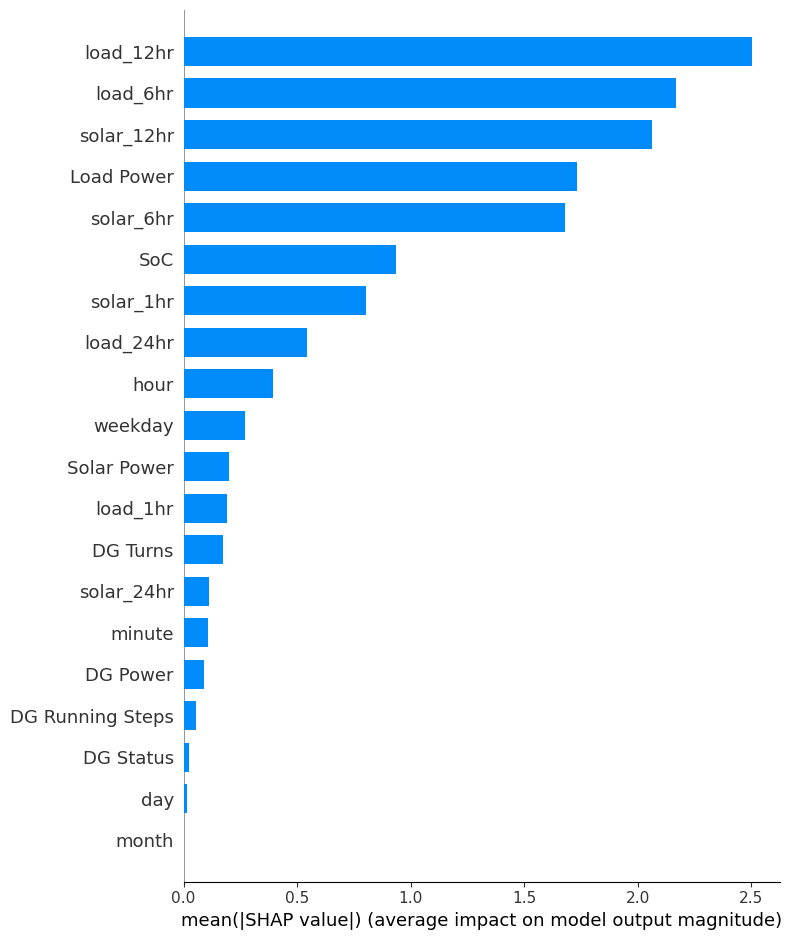


🔍 SHAP Summary for Action 1


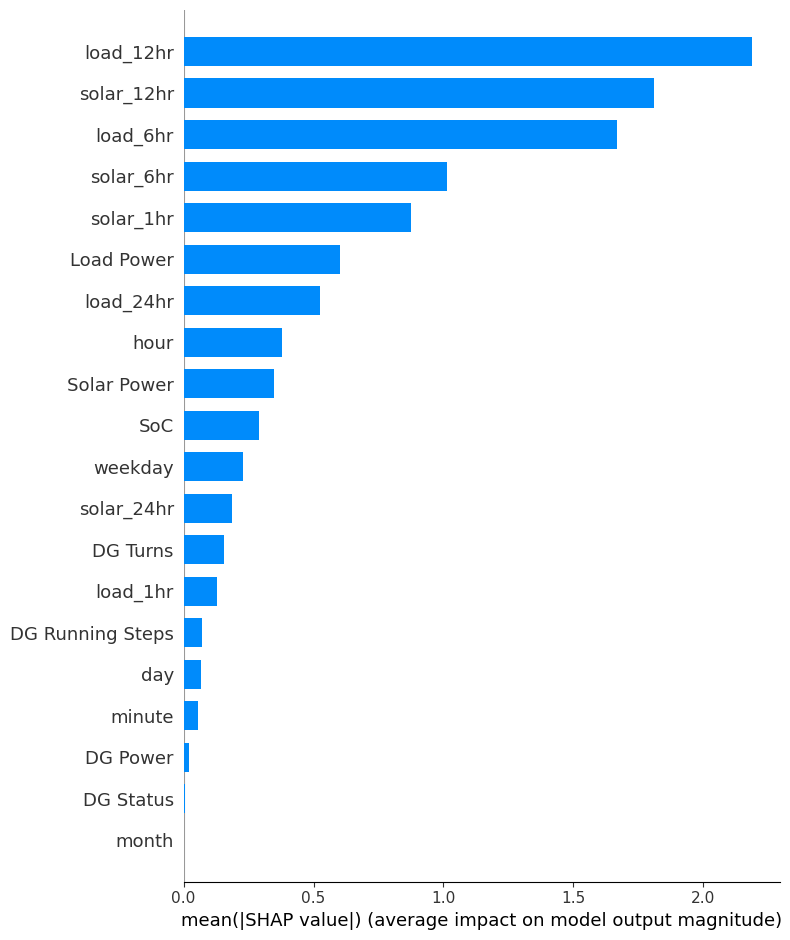

In [712]:
f = ['year','month','weekday','day','hour','minute','SoC','Load Power','Solar Power','DG Power','DG Turns','DG Status','DG Running Steps',
    'load_1hr','solar_1hr','load_6hr','solar_6hr','load_12hr','solar_12hr','load_24hr','solar_24hr']

for action in range(shap_values.shape[2]):
    print(f"\n🔍 SHAP Summary for Action {action}")
    
    # Extract SHAP values for this action
    shap_values_action = shap_values[:, :, action]  # shape = (N, 21)
    
    # Create summary plot
    shap.summary_plot(shap_values_action, sample_data, 
                      feature_names=f,
                      plot_type="bar") 

In [ ]:
from tensorflow.keras.models import load_model

q_net = load_model('Models/rl_2.h5')

# converter = tf.lite.TFLiteConverter.from_keras_model(model)
# tflite_model = converter.convert()

# # Save the TFLite model
# with open("model.tflite", "wb") as f:
#     f.write(tflite_model)

In [762]:
converter = tf.lite.TFLiteConverter.from_keras_model(q_net)
tflite_model = converter.convert()

interpreter = tf.lite.Interpreter(model_content=tflite_model)
interpreter.allocate_tensors()

INFO:tensorflow:Assets written to: C:\Users\hps10\AppData\Local\Temp\tmprtkl2niq\assets


INFO:tensorflow:Assets written to: C:\Users\hps10\AppData\Local\Temp\tmprtkl2niq\assets


Saved artifact at 'C:\Users\hps10\AppData\Local\Temp\tmprtkl2niq'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 19), dtype=tf.float32, name='keras_tensor_389')
Output Type:
  TensorSpec(shape=(None, 2), dtype=tf.float32, name=None)
Captures:
  2132665118416: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2132665109200: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2132665113040: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2132665110544: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2132665109392: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2132665116304: TensorSpec(shape=(), dtype=tf.resource, name=None)


In [768]:
input_details = interpreter.get_input_details()
output_details = interpreter.get_output_details()

print("Input details:", input_details)
print("Output details:", output_details)

Input details: [{'name': 'serving_default_keras_tensor_389:0', 'index': 0, 'shape': array([ 1, 19]), 'shape_signature': array([-1, 19]), 'dtype': <class 'numpy.float32'>, 'quantization': (0.0, 0), 'quantization_parameters': {'scales': array([], dtype=float32), 'zero_points': array([], dtype=int32), 'quantized_dimension': 0}, 'sparsity_parameters': {}}]
Output details: [{'name': 'StatefulPartitionedCall_1:0', 'index': 9, 'shape': array([1, 2]), 'shape_signature': array([-1,  2]), 'dtype': <class 'numpy.float32'>, 'quantization': (0.0, 0), 'quantization_parameters': {'scales': array([], dtype=float32), 'zero_points': array([], dtype=int32), 'quantized_dimension': 0}, 'sparsity_parameters': {}}]


In [770]:
# Save the TFLite model
with open("rl_3.tflite", "wb") as f:
    f.write(tflite_model)